1.-Carga y creación 

In [1]:
import sys; sys.path.append("..")
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.datos import cargar_obt
from src import pipeline as P

df = P.agregar_features(cargar_obt())
df[["fecha_coccion", "coccion_mes", "carga_planta_14d", "temporada_alta", "generacion_levadura", "levadura_nueva"]].head(10)

,fecha_coccion,coccion_mes,carga_planta_14d,temporada_alta,generacion_levadura,levadura_nueva
0,2026-01-30,1,0,0.0,NaN,NaN
1,2026-01-30,1,0,0.0,NaN,NaN
2,2026-01-31,1,2,0.0,NaN,NaN
3,2026-02-02,2,3,0.0,2.0,0.0
4,2026-02-03,2,4,0.0,3.0,0.0
5,2026-02-04,2,5,0.0,3.0,0.0
6,2026-02-05,2,6,0.0,3.0,0.0
7,2026-02-09,2,7,0.0,2.0,0.0
8,2026-02-09,2,7,0.0,2.0,0.0
9,2026-02-09,2,7,0.0,4.0,0.0


2.- Importancia de features 

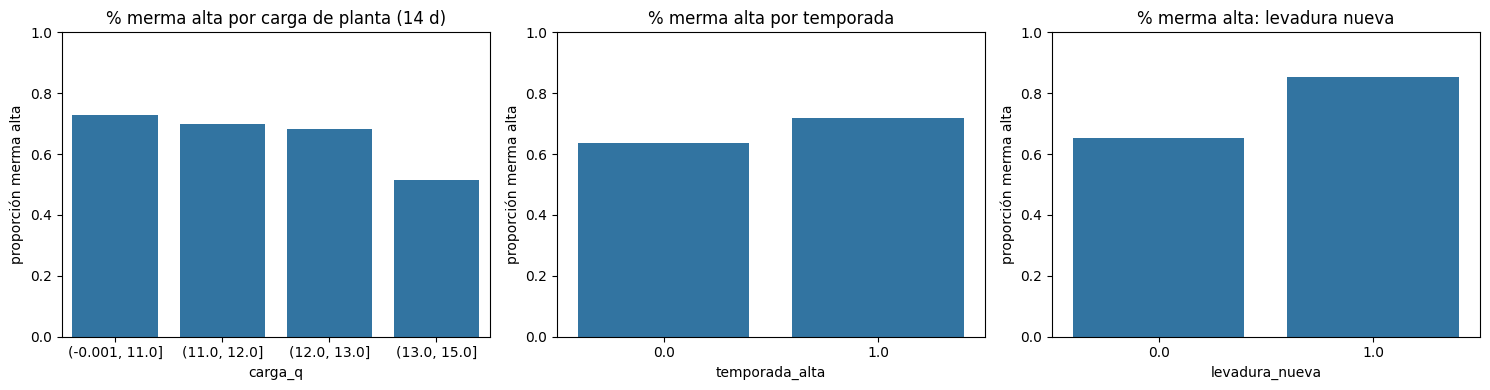

carga_planta_14d   -0.167
temporada_alta      0.149
levadura_nueva      0.222
merma_pct           1.000
Name: merma_pct, dtype: float64


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df["carga_q"] = pd.qcut(df["carga_planta_14d"], 4, duplicates="drop")
sns.barplot(data=df, x="carga_q", y="merma_alta", ax=ax[0], errorbar=None); ax[0].set_title("% merma alta por carga de planta (14 d)")
sns.barplot(data=df, x="temporada_alta", y="merma_alta", ax=ax[1], errorbar=None); ax[1].set_title("% merma alta por temporada")
sns.barplot(data=df, x="levadura_nueva", y="merma_alta", ax=ax[2], errorbar=None); ax[2].set_title("% merma alta: levadura nueva")
for a in ax: a.set_ylim(0, 1); a.set_ylabel("proporción merma alta")
plt.tight_layout(); plt.savefig("../docs/figs/05_features.png", dpi=150); plt.show()

print(df[["carga_planta_14d", "temporada_alta", "levadura_nueva", "merma_pct"]]
      .corr(method="spearman")["merma_pct"].round(3))

3.- Prueba de que no hay fuga de datos 

In [3]:
FUGA = ["cantidad_completada", "merma_litros", "merma_ajustada", "fecha_cierre", "dias_proceso"] \
       + [c for c in df.columns if c.startswith("cierre_")] + ["merma_pct"]
assert not set(P.FEATURES) & set(FUGA), "¡Hay una feature con fuga!"
print("Features del modelo:", P.FEATURES)
print("Ninguna feature usa información posterior a la cocción ✔")

# La carga de un lote solo cuenta cocciones ANTERIORES: ejemplo con un lote cualquiera
i = 100
f = df.loc[i, "fecha_coccion"]
manual = ((df["fecha_coccion"] >= f - pd.Timedelta(days=14)) & (df["fecha_coccion"] < f)).sum()
print(f"Lote {df.loc[i,'numero_documento']} ({f.date()}): carga calculada={df.loc[i,'carga_planta_14d']}, recuento manual={manual}")

Features del modelo: ['generacion_levadura', 'n_cocciones', 'coccion_mes', 'coccion_dia_semana', 'carga_planta_14d', 'levadura_nueva', 'sin_generacion', 'con_microscopio', 'temporada_alta', 'cepa']
Ninguna feature usa información posterior a la cocción ✔
Lote 647 (2026-05-25): carga calculada=15, recuento manual=15


4.- División y validación cruzada 

In [4]:
train, test = P.dividir_train_test(df)
print(f"Train: {len(train)} lotes  {train.fecha_coccion.min().date()} → {train.fecha_coccion.max().date()} | % alta {train.merma_alta.mean():.0%}")
print(f"Test:  {len(test)} lotes  {test.fecha_coccion.min().date()} → {test.fecha_coccion.max().date()} | % alta {test.merma_alta.mean():.0%}")

for k, (i_tr, i_va) in enumerate(P.esquema_cv().split(train), 1):
    tr, va = train.iloc[i_tr], train.iloc[i_va]
    print(f"Pliegue {k}: entrena hasta {tr.fecha_coccion.max().date()} ({len(tr)}) | valida {va.fecha_coccion.min().date()}→{va.fecha_coccion.max().date()} ({len(va)}) | % alta val {va.merma_alta.mean():.0%}")

Train: 176 lotes  2026-01-30 → 2026-08-14 | % alta 64%
Test:  45 lotes  2026-08-17 → 2026-10-13 | % alta 80%
Pliegue 1: entrena hasta 2026-03-05 (31) | valida 2026-03-06→2026-04-09 (29) | % alta val 55%
Pliegue 2: entrena hasta 2026-04-09 (60) | valida 2026-04-10→2026-05-14 (29) | % alta val 90%
Pliegue 3: entrena hasta 2026-05-14 (89) | valida 2026-05-14→2026-06-13 (29) | % alta val 55%
Pliegue 4: entrena hasta 2026-06-13 (118) | valida 2026-06-15→2026-07-13 (29) | % alta val 76%
Pliegue 5: entrena hasta 2026-07-13 (147) | valida 2026-07-14→2026-08-14 (29) | % alta val 55%


5.- Funcionamiento del pipeline 

In [5]:
from sklearn.dummy import DummyClassifier
X_tr, y_tr = P.preparar_X_y(train)
pipe = P.construir_pipeline(DummyClassifier()).fit(X_tr, y_tr)
print("Columnas después de la preparación:")
print(list(pipe.named_steps["prep"].get_feature_names_out()))

Columnas después de la preparación:
['num__generacion_levadura', 'num__n_cocciones', 'num__coccion_mes', 'num__coccion_dia_semana', 'num__carga_planta_14d', 'num__missingindicator_generacion_levadura', 'bin__levadura_nueva', 'bin__sin_generacion', 'bin__con_microscopio', 'bin__temporada_alta', 'cat__cepa_BE-256', 'cat__cepa_K-97', 'cat__cepa_US-05', 'cat__cepa_W34/70']


Features derivadas

Levadura nueva: el 86 % de los lotes con levadura nueva tuvo merma alta, frente al 65 % de los lotes con levadura reutilizada (Spearman 0.22). La generación se registra el día de la cocción. Se codifica como binaria 0/1.

Temporada alta (derivada del hallazgo 4): 72 % de lotes con merma alta en abril, mayo, junio y agosto, frente al 63 % del resto del año (Spearman 0.15). En esos meses se acelera la fermentación y se recortan el lagering y el cold crash. Depende solo del mes de cocción. Se codifica como binaria 0/1.

Carga de planta en 14 días (derivada del hallazgo 4): a mayor carga, menos lotes con merma alta (de 73 % a 52 %, Spearman −0.17). Es contrario a lo esperado y probablemente refleja que en esas semanas se produce más American Lager. Solo cuenta lotes cocinados antes de este lote. Es numérica y se escala.

Cepa: la BE-256 tiene una mediana de merma cercana al 22 %. Se usa en lugar del estilo porque varios estilos tienen muy pocos lotes. Se conoce al planificar el lote. Se codifica con One-Hot.

Sin fuga: ninguna feature usa datos del cierre del lote. El microscopio se excluye porque solo hay datos desde agosto y los pliegues de entrenamiento no los tienen.

Validación

Hold-out temporal con el último 20 % de los lotes: 176 de entrenamiento (enero a agosto) y 45 de prueba (agosto a octubre). Validación cruzada con TimeSeriesSplit de 5 pliegues, siempre entrenando con el pasado, por la estacionalidad y la reutilización de levadura. La preparación de los datos está en src/pipeline.py y se ajusta solo con el entrenamiento de cada pliegue. El porcentaje de lotes con merma alta varía entre 55 % y 90 % según el pliegue, así que se reporta la desviación entre pliegues.